# Лекція 5. Локальний деплоймент і оптимізація моделей

Демо до лекції. Усі моделі запускаємо локально через [Ollama](https://ollama.com) і звертаємося до нього звичайними HTTP-запитами.

## Відповіді на питання

1. Модель (що з міркуванням, що без) працює з токенами, а не з літерами. Наприклад, слово «трансформер» вона бачить як декілька підслів, тому завдання на рівні окремих літер (підрахунок, зворотний порядок, акровірші) для моделі неприродні. Модель могла б "пригадати" інформацію про кількість літер в слові з навчальних даних, але ймовірно дана модель навіть не вчилась на українській мові.

``` python
word = "трансформер"
ids = tokenizer(word, add_special_tokens=False).input_ids
print([tokenizer.decode([i]) for i in ids])
print("Токенів:", len(ids))
print("Літер:", len(word))
print(word.count("р"))
```
```
['т', 'ран', 'с', 'форм', 'ер']
Токенів: 5
Літер: 11
3
```

2. З використанням fp16 та int8 перплексія не змінюється. В int4 трохи зростає. А з використанням int2 модель повністю ламається. Найбільший стрибок між int4 та int2. fp16 показує найкращі метрики перекладу. На int8 і int4 вони коливаються без тренду (значення BLEU навіть виросло на int4), ймовірно через малу вибірку. int 2 також показала погані результати.

3. На int4 перплексія англійської зросла на ~5% (з 2.67 до 2.81), а для української на ~15% (з 2.40 до 2.76). На int2 значення перплексії для української приблизно в 550 разів більше, ніж для англійської. Це відповідає висновку з презентації:

- "Малі моделі страждають сильніше: у моделі на 1–3B кожен параметр важить більше, ніж у моделі на 70B."
- "Першими ламаються математика й складні міркування, а також мови з нелатинською абеткою — зокрема й українська."

4. Мої вибори:
```python
VOTES = {1: "A", 2: "A", 3: "B", 4: "A", 5: "A"}
```
```
запит                                                        A    B    ваш вибір
0    Напиши короткий лист викладачеві з проханням п...    fp16    int4    fp16
1    Поясни студентові першого курсу в 3–4 реченнях...    fp16    int4    fp16
2    Explain in three sentences why the sky is blue.    fp16    int4    int4
3    Склади план підготовки до іспиту з програмуван...    int4    fp16    int4
4    Write a Python function that checks whether a ...    int4    fp16    int4

fp16 краща: 2, int4 краща: 3, однаково: 0

```

Ці результати збігаються з метриками, адже вони показали лише невелике погіршення при використанні int4

5.
```python
from pprint import pprint
ref = TRANSLATION[3][1]
print("Еталон: ", ref)
for q in ("fp16", "int8", "int4"):
  transl = records[q]["переклади"][3]
  print(q)
  print(f" transl:", transl)
  print(" chrF:", chrf.compute(predictions=[transl], references=[[ref]])["score"])
  print(" BLEU:", bleu.compute(predictions=[transl], references=[[ref]])["score"])
```
```
Еталон:  Наша команда виправила помилку, але тести все ще не проходять.
fp16
 transl: Наша команда виправила баг, але тестування все ще не працюють.
 chrF: 60.679148630908585
 BLEU: 24.808415001701817
int8
 transl: Наша команда виправила баг, але тестування все ще не працюють.
 chrF: 60.679148630908585
 BLEU: 24.808415001701817
int4
 transl: Наша команда виправила баг, але тести все ще не працюють.
 chrF: 68.45623306101312
 BLEU: 54.52469119630863
```
chrF м'якший, він враховує спільні фрагменти слів та дає частковий бал. BLEU реагує сильніше. Він рахує збіги цілих слів тож кожне слово, що відрізняється, погіршує оцінку.

6. Пам'ять модель зменшилася в ~1.8 раза для int8, ~2.9 раза для int4 і ~4.4 раза для int2. Не 2×/4×/8×, бо квантизуються лише ваги, а є ще KV-кеш, активації й буфери рантайму. Генерація сповільнилася: 14.24 tok/s (fp16), 5.34 (int8), 2.72 (int4), 2.77 (int2). T4 не вміє множити в цих форматах, тому ваги щоразу розпаковуються в fp16.

7. Base-модель навчена лише передбачати наступний токен. «Яка столиця Франції?» схоже на рядок зі списку питань вікторини, тож модель просто вигадує питання далі.
```python
prompt = ("Питання: Яка столиця Німеччини?\nВідповідь: Берлін\n\n"
          "Питання: Яка столиця Франції?\nВідповідь:")
print(generate_raw(BASE_MODEL, prompt, max_tokens=8).split("\n")[0])
```
```
Паризька
```

8. Без міркувань: 255 токенів, 2.2 с. З міркуванням: 624 токени, 5.7 с, тобто приблизно в 2.4 разів більше токенів і 2.6 разів більше часу, і це лише на простій задачі. Модель міркує англійською, бо її навчальні дані й особливо дані для ланцюжків міркувань переважно англійські. Англійською мала модель міркує надійніше, ніж українською, а фінальну відповідь вона формує мовою користувача.

9.

```python
import re

def last_number(text):
    text = re.sub(r"(?<=\d)[ \u00a0,](?=\d{3}\b)", "", text)
    nums = re.findall(r"-?\d+", text)
    return nums[-1] if nums else None

SUFFIX = " Відповідай одним числом, без пояснень."
tasks = [
    ("Скільки буде 347 × 29?", "10063"),
    ("Скільки буде 48 × 25 + 17 × 36?", "1812"),
    ("Яка сума всіх цілих чисел від 1 до 100, які діляться на 7?", "735"),
    ("Скільки простих чисел між 50 і 70?", "4"),
    ("У Олени втричі більше цукерок, ніж у Максима. Якщо Олена віддасть Максиму 10 цукерок, "
     "у них стане порівну. Скільки цукерок було в Олени?", "30"),
    ("Через 5 років Оксані буде вдвічі більше років, ніж було їй 7 років тому. "
     "Скільки років Оксані зараз?", "19"),
]

for question, answer in tasks:
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, question + SUFFIX, think=think,
                 max_tokens=3000 if think else 40)
        out = r["message"]["content"].strip()
        got = last_number(out)
        print(f"{question[:45]:45} | think={think!s:5} | очікується {answer:>5} | "
              f"{'правильно' if got == answer else 'не правильно'} | {out[:70]!r}")
    print()
```

```
Скільки буде 347 × 29?                        | think=False | очікується 10063 | правильно | '347 × 29 = 10063'
Скільки буде 347 × 29?                        | think=True  | очікується 10063 | правильно | '10063'

Скільки буде 48 × 25 + 17 × 36?               | think=False | очікується  1812 | не правильно | '48 × 25 + 17 × 36 = (48 × 25) + (17 × 36)  \n= 1200 +'
Скільки буде 48 × 25 + 17 × 36?               | think=True  | очікується  1812 | правильно | '1812'

Яка сума всіх цілих чисел від 1 до 100, які д | think=False | очікується   735 | не правильно | 'Сума всіх цілих чисел від 1 до 100, які діляться на 7, дорівнює:\n\n$$'
Яка сума всіх цілих чисел від 1 до 100, які д | think=True  | очікується   735 | правильно | '735\n\nВідповідь: \\boxed{735}'

Скільки простих чисел між 50 і 70?            | think=False | очікується     4 | не правильно | '17, 19, 23, 29, 31, 37, 41, 43, 47, 53,'
Скільки простих чисел між 50 і 70?            | think=True  | очікується     4 | правильно | '4'

У Олени втричі більше цукерок, ніж у Максима. | think=False | очікується    30 | не правильно | 'Позначимо, що у Олени було $ x $ цукерок.  \nУ Максима — $ \\frac{x}{3} '
У Олени втричі більше цукерок, ніж у Максима. | think=True  | очікується    30 | правильно | '30'

Через 5 років Оксані буде вдвічі більше років | think=False | очікується    19 | не правильно | 'Позначимо за $ x $ — це сьогодні роки Оксані.\n\nПісля 5 років Оксані'
Через 5 років Оксані буде вдвічі більше років | think=True  | очікується    19 | правильно | '19'
```

10. Нульова температура робить генерацію дуже передбачуваною: на кожному кроці береться токен з найбільшою ймовірністю, тож випадковості немає. seed фіксує генератор випадкових чисел. Разом вони роблять експерименти відтворюваними, а порівняння чесним: різниця між Base та Instruct чи think=True та think=False походить від моделі й режиму, а не від випадкового семплінгу.

11. T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна. torch.cuda.get_device_capability() на T4 повертає (7, 5), бо це архітектура Turing. Апаратна підтримка bf16 з'явилася з Ampere, тобто з (8, 0) і вище.

12. Qwen3-4B-Instruct-2507 має 4.0 млрд параметрів. Формула:
Памʼять (GB)≈ P × (Q/8) × (1+O)
де P — параметри в мільярдах, Q — біт на параметр, O - overhead (10–30%)

За формулою: 4*10^9 * 2 * 1.2 = 9.6*10^9 GB

Значення з таблиці: 8.04 GB

13. Переплексія це метрика, що показує з скількох рівноймовірних варіантів модель у середньому вибирала наступний токен. Чим ця метрика менша, тим краще модель знає мову й тему. Порівнювати мови не можна, бо токенізація різна. Один зміст українською розпадається на інше число токенів, і багато з них є легкими продовженнями слова, що знижує середню похибку. Тому значення перплексії для української (2.40) є нижчим за її значення для англійської (2.67), хоча англійську модель знає не гірше.

```python
import re, random

gc.collect(); torch.cuda.empty_cache()
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)

for lang, text in PPL_TEXT.items():
    words = re.findall(r"\w+", text.lower())
    shuffled = words[:]
    random.Random(0).shuffle(shuffled)
    print("Мова:", lang)
    print(" Перплексія для осмисленого тексту:", round(perplexity(model, text), 2))
    print(" Перплексія для випадкового порядку слів:", round(perplexity(model, " ".join(shuffled)), 2))

del model
```
```
Loading weights: 100%
 398/398 [00:36<00:00, 12.21it/s]
Мова: English
 Перплексія для осмисленого тексту: 2.67
 Перплексія для випадкового порядку слів: 308.79
Мова: Українська
 Перплексія для осмисленого тексту: 2.4
 Перплексія для випадкового порядку слів: 12.84
```
Найімовірніша причина результатів в токенізації. Перплексія усереднюється за токенами, а не за словами.
Для англійської більшість слів це один токен. Кожен токен є передбаченням цілого слова, і після перемішування слів ці передбачення стають майже випадковими.
Для української токенізатор Qwen розбиває слово на кілька підслів. Лише перший токен слова справді залежить від контексту. Другий і наступні токени (закінчення, суфікси) вгадуються з самого слова, тому їхня похибка майже нульова, навіть коли порядок слів зіпсований. Ці «безкоштовні» токени розбавляють середнє, і вийшло лише ~13.

14. memory_allocated міряється одразу після завантаження, а пік охоплює ще й роботу: активації, логіти, KV-cache, тимчасові буфери та розпаковку int4/int2-ваг у fp16.

15. fp16 обрано 2 рази, int4 3 рази, однаково 0. Висновків робити не можна, адже вибірка надто мала. Для надійного висновку потрібні десятки запитів, а краще кілька сотень. Якщо різниця між моделями невелика (скажімо, одна виграє у 55-60% випадків), то щоб її помітити, потрібно приблизно 100-200 порівнянь.

16. Відповіді моделі, що використовує int2 не стосуються запиту та часто зациклені на одному токені. Модель не розуміє ні мову запиту, ні формат діалогу, і жодної відповіді навіть не починає. Хоча відповіді у моделі з int4 мають певні дефекти, але вони набато кращі за int2.

17. Так, 4-бітна квантизація б'є по меншій моделі помітно сильніше. Порівняння перплексії:
```
4B
      перплексія, English  перплексія, Українська
int8                 1.00                    1.00
int4                 1.05                    1.15
int2             22884.69             14078881.67

1.7B
      перплексія, English  перплексія, Українська
int8                 1.03                    1.01
int4                 1.73                    1.82
int2            101442.97              1907622.82
```
Модель практично не справляється з перекладом, тож метрика chrF показує погані результати:
fp6 8.61
int8 9.13
int4 10.1
int2 0.16

18. Це кількість запитів, які Ollama обробляє одночасно для однієї завантаженої моделі. Кожен запит дістає власний слот із власним KV-cache, а llama.cpp об'єднує їх в один батч. Ваги читаються один раз на кілька послідовностей, і сумарна пропускна здатність зростає, бо генерація впирається в пам'ять, а не в обчислення.

19. Він має 8 біт виділених підекспоненту, як і fp32, тому діапазон значень той самий (до ~3*10^38), а мантиса у нього коротша (7 біт проти 10 у fp16). fp16 переповнюється вже на 65504, а bf16 здатний працювати з набагато більшими значеннями. Нейромережі нечутливі до втрати точності мантиси, а в пам'яті bf16 займає стільки ж, скільки fp16. Тренується більшість моделей саме в bf16, тож зберігати їх у ньому означає не втрачати нічого при перетворенні.

20. ChatGPT та його API першими закріпили формат чату і навколо нього виросла вся екосистема. Ollama, vLLM, llama.cpp server і LM Studio реалізують один і той самий інтерфейс, щоб наявні клієнти працювали з локальною моделлю за допомогою зміни одного base_url, без переписування коду й прив'язки до постачальника.

## 0. Налаштування середовища

### 0.0. Імпортуємо бібліотеки

In [1]:
import json
import subprocess
import sys
import time
import urllib.request

OLLAMA_URL = "http://localhost:11434"

### 0.1. Встановлюємо й запускаємо Ollama

Локально цю клітинку можна просто виконати: вона нічого не зробить.

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    !sudo apt-get -qq install -y zstd > /dev/null
    !curl -fsSL https://ollama.com/install.sh | sh
    subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    time.sleep(5)

Running in Colab: True
debconf: unable to initialize frontend: Dialog
debconf: (No usable dialog-like program is installed, so the dialog based frontend cannot be used. at /usr/share/perl5/Debconf/FrontEnd/Dialog.pm line 79, <STDIN> line 1.)
debconf: falling back to frontend: Readline
debconf: unable to initialize frontend: Readline
debconf: (This frontend requires a controlling tty.)
debconf: falling back to frontend: Teletype
dpkg-preconfigure: unable to re-open stdin: 
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Creating ollama user...
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


### 0.2. Перевіряємо, що Ollama працює

Ollama — це HTTP-сервер на порту 11434. Функція `ollama()` надсилає йому запит і повертає відповідь як словник Python; якщо сервер працює, побачимо його версію.

In [3]:
def ollama(path, body=None, timeout=900):
    """POST-запит до Ollama (або GET, якщо body=None); повертає розібраний JSON."""
    data = json.dumps(body).encode() if body is not None else None
    req = urllib.request.Request(OLLAMA_URL + path, data=data, headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=timeout) as resp:
        return json.load(resp)


print("Ollama version:", ollama("/api/version")["version"])

Ollama version: 0.40.7


## 1. Base, Instruct і Thinking

Порівнюємо три поведінки однієї й тієї самої моделі Qwen3 1.7B:
- **Base-модель** пройшла лише попереднє тренування: вона вміє передбачати наступний токен в інтернет-текстах, але не вміє відповідати на питання як асистент.
- **Instruct-модель** додатково донавчили на прикладах «інструкція → відповідь» у форматі діалогу.
- **Thinking** — режим, у якому Instruct-модель перед відповіддю генерує ланцюжок міркувань.

### 1.0. Завантажуємо моделі

Беремо одну й ту саму модель Qwen3 1.7B у двох версіях:
- **Base** — [Qwen3-1.7B-Base](https://huggingface.co/Qwen/Qwen3-1.7B-Base) у форматі GGUF (Q4_K_M) з Hugging Face;
- **Instruct** — офіційна [qwen3:1.7b](https://ollama.com/library/qwen3) з каталогу Ollama; вона ж уміє працювати в режимі міркування.

Перше завантаження займає кілька хвилин.

In [4]:
BASE_MODEL = "hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M"
INSTRUCT_MODEL = "qwen3:1.7b"

for m in (BASE_MODEL, INSTRUCT_MODEL):
    print("pull", m, "→", ollama("/api/pull", {"model": m, "stream": False})["status"])

pull hf.co/mradermacher/Qwen3-1.7B-Base-GGUF:Q4_K_M → success
pull qwen3:1.7b → success


### 1.1. Допоміжні функції

Нам вистачить двох ендпойнтів Ollama:
- `/api/generate` з `"raw": true` — передає моделі текст як є, **без chat template**;
- `/api/chat` — приймає список повідомлень і сам загортає їх у chat template моделі.

У Qwen3 режим міркування вмикається параметром `think`. З `think=True` модель спершу генерує ланцюжок міркувань (Ollama повертає його окремим полем `message.thinking`), а вже потім — відповідь. Функція `compare_thinking()` запускає запит в обох режимах і показує відповідь, кількість згенерованих токенів і час.

In [5]:
def generate_raw(model, prompt, max_tokens=120):
    """Продовження тексту без chat template — так «бачить» запит Base-модель."""
    r = ollama("/api/generate", {
        "model": model, "prompt": prompt, "raw": True, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })
    return r["response"]


def chat(model, prompt, think=False, max_tokens=3000):
    """Один запит у форматі діалогу; think=True вмикає режим міркування."""
    return ollama("/api/chat", {
        "model": model, "messages": [{"role": "user", "content": prompt}],
        "think": think, "stream": False,
        "options": {"temperature": 0, "seed": 1, "num_predict": max_tokens},
    })


def compare_thinking(prompt):
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, prompt, think=think)
        msg = r["message"]
        print(f"=== think={think} | токенів: {r['eval_count']} | генерація: {r['eval_duration'] / 1e9:.1f} с")
        if msg.get("thinking"):
            print(f"--- міркування ({len(msg['thinking'])} символів), початок:")
            print(msg["thinking"][:600], "…")
        print("--- відповідь:")
        print(msg["content"])
        print()

### 1.2. Base: модель просто продовжує текст

Поставимо Base- та Instruct-моделі однакове питання.

In [6]:
QUESTION = "Яка столиця Франції?"

In [7]:
print(generate_raw(BASE_MODEL, QUESTION))

 Як називається найбільша річка Франції? Як називається найбільша річка Франції, яка розташована в Північній Америці? Як називається найбільша річка Франції, яка розташована в Півдні Франції? Як називається найбільша р


Для Base-моделі «Яка столиця Франції?» схоже на початок списку питань вікторини — тож вона продовжує цей список, а не відповідає.

In [8]:
prompt = ("Питання: Яка столиця Німеччини?\nВідповідь: Берлін\n\n"
          "Питання: Яка столиця Франції?\nВідповідь:")
print(generate_raw(BASE_MODEL, prompt, max_tokens=8).split("\n")[0])

 Паризька


In [30]:
import re

def last_number(text):
    text = re.sub(r"(?<=\d)[ \u00a0,](?=\d{3}\b)", "", text)
    nums = re.findall(r"-?\d+", text)
    return nums[-1] if nums else None

SUFFIX = " Відповідай одним числом, без пояснень."
tasks = [
    ("Скільки буде 347 × 29?", "10063"),
    ("Скільки буде 48 × 25 + 17 × 36?", "1812"),
    ("Яка сума всіх цілих чисел від 1 до 100, які діляться на 7?", "735"),
    ("Скільки простих чисел між 50 і 70?", "4"),
    ("У Олени втричі більше цукерок, ніж у Максима. Якщо Олена віддасть Максиму 10 цукерок, "
     "у них стане порівну. Скільки цукерок було в Олени?", "30"),
    ("Через 5 років Оксані буде вдвічі більше років, ніж було їй 7 років тому. "
     "Скільки років Оксані зараз?", "19"),
]

for question, answer in tasks:
    for think in (False, True):
        r = chat(INSTRUCT_MODEL, question + SUFFIX, think=think,
                 max_tokens=3000 if think else 40)
        out = r["message"]["content"].strip()
        got = last_number(out)
        print(f"{question[:45]:45} | think={think!s:5} | очікується {answer:>5} | "
              f"{'правильно' if got == answer else 'не правильно'} | {out[:70]!r}")
    print()

Скільки буде 347 × 29?                        | think=False | очікується 10063 | правильно | '347 × 29 = 10063'
Скільки буде 347 × 29?                        | think=True  | очікується 10063 | правильно | '10063'

Скільки буде 48 × 25 + 17 × 36?               | think=False | очікується  1812 | не правильно | '48 × 25 + 17 × 36 = (48 × 25) + (17 × 36)  \n= 1200 +'
Скільки буде 48 × 25 + 17 × 36?               | think=True  | очікується  1812 | правильно | '1812'

Яка сума всіх цілих чисел від 1 до 100, які д | think=False | очікується   735 | не правильно | 'Сума всіх цілих чисел від 1 до 100, які діляться на 7, дорівнює:\n\n$$'
Яка сума всіх цілих чисел від 1 до 100, які д | think=True  | очікується   735 | правильно | '735\n\nВідповідь: \\boxed{735}'

Скільки простих чисел між 50 і 70?            | think=False | очікується     4 | не правильно | '17, 19, 23, 29, 31, 37, 41, 43, 47, 53,'
Скільки простих чисел між 50 і 70?            | think=True  | очікується     4 | правильно | '4'

У

### 1.3. Instruct: модель відповідає на питання

In [10]:
print(chat(INSTRUCT_MODEL, QUESTION)["message"]["content"])

Столиця Франції — це місто **Париж**.


### 1.4. Instruct проти Thinking: багатокрокова задача

In [11]:
compare_thinking(
    "У кошику 3 яблука. Марія поклала туди ще 2 пакети по 4 яблука, "
    "а потім зʼїла 2 яблука. Скільки яблук у кошику?"
)

=== think=False | токенів: 254 | генерація: 2.2 с
--- відповідь:
Розглянемо ситуацію крок за кроком:

1. **У кошику 3 яблука.**  
2. **Марія поклала туди ще 2 пакети по 4 яблука.**  
   - Кожен пакет містить 4 яблука, тому:
     $$
     2 \text{ пакети} \times 4 \text{ яблука} = 8 \text{ яблука}
     $$
   - Значить, після додавання пакетів у кошик буде:
     $$
     3 + 8 = 11 \text{ яблука}
     $$
3. **Марія зʼїла 2 яблука.**  
   - Після з’ївання:
     $$
     11 - 2 = 9 \text{ яблука}
     $$

**Відповідь:** У кошику **9 яблук**.

=== think=True | токенів: 575 | генерація: 5.1 с
--- міркування (1452 символів), початок:
Okay, let's see. So the problem is about Marry putting some apples in a basket and then eating some. Let me try to break it down step by step.

First, the basket starts with 3 apples. Then, Maria puts 2 packs into the basket. Each pack has 4 apples. So, I need to figure out how many apples she adds in total. Since there are 2 packs, each with 4 apples, that would be

Обидва режими відповідають правильно, але з міркуванням модель генерує в кілька разів більше токенів — а користувач бачить відповідь лише після них. Зверніть увагу: міркує модель англійською, хоча питання українською.

### 1.5. Міркування не гарантують правильності

In [12]:
compare_thinking("Скільки разів літера «р» трапляється в слові «трансформер»?")

=== think=False | токенів: 198 | генерація: 1.7 с
--- відповідь:
Щоб визначити, скільки разів літера **«р»** трапляється в слові **«трансформер»**, зробимо так:

Слово: **трансформер**

Розбілем його на складніше:

- **трансформер**  
  Розбиття: **транс** + **формер**

Тепер зіштовхнемо літеру **«р»**:

- **транс** — не має «р»  
- **формер** — має **«р»** (1 раз)

Отже, літера **«р»** трапляється **1 раз** в слові **«трансформер»**.

**Відповідь: 1**

=== think=True | токенів: 644 | генерація: 5.8 с
--- міркування (1539 символів), початок:
Okay, let's see. The user is asking how many times the letter "р" appears in the word "трансформер". First, I need to make sure I know the correct spelling of the word. The word in question is "трансформер". Let me write it out: трансформер.

Now, I need to check each letter one by one. Let's start from the beginning. The first letter is "т" which is "t" in Ukrainian, but the question is about the letter "р". So, the first letter is "т", not "р". M

Правильна відповідь — 3 (т**р**ансфо**р**ме**р**), але мала модель помиляється в обох режимах. Чому так — подумайте самі (це питання до лабораторної роботи).

Спробуйте власні запити: де режим міркування справді допомагає, а де лише витрачає токени?

## 2. Квантизація з Quanto

Завантажимо ту саму модель у чотирьох варіантах — від оригінальних 16 біт до 2 біт — і подивимося, що квантизація змінює в памʼяті, швидкості та якості. Якість перевіримо трьома способами: перплексією, перекладом з автоматичними метриками й очима — на вільній генерації тексту.

**Quanto.** [Optimum Quanto](https://github.com/huggingface/optimum-quanto) — бібліотека квантизації від Hugging Face, один із бекендів [Optimum](https://huggingface.co/docs/optimum). У Transformers вона підключається через [`QuantoConfig`](https://huggingface.co/docs/transformers/quantization/quanto) і квантизує модель прямо під час завантаження, тому окремий файл з квантизованими вагами не потрібен. Квантизуються ваги лінійних шарів (`nn.Linear`) — у них більшість параметрів моделі, а ембединги, нормалізації та вихідний шар лишаються в 16 бітах.

| Варіант | Біт на вагу | Що це |
|---|---|---|
| fp16 | 16 | Оригінальні ваги, точка відліку |
| int8 | 8 | 8-бітні цілі числа з масштабом |
| int4 | 4 | 4-бітні цілі числа, ваги діляться на блоки з власними масштабами |
| int2 | 2 | 2-бітні цілі числа — лише 4 можливі значення на вагу; тут модель має зламатися |

**Обчислення.** Множити числа в цих форматах напряму T4 не вміє, тому перед множенням ваги розпаковуються в 16 біт. Тому памʼяті потрібно менше, а от генерація часто **не прискорюється**, а то й сповільнюється.

**Де запускати.** Секцію запускаємо **в Google Colab на GPU T4** (Runtime → Change runtime type → T4 GPU). Беремо формат **fp16**, а не bf16: T4 не підтримує bf16 апаратно, а для запуску готової моделі різниця між ними практично непомітна.

### 2.0. Встановлюємо бібліотеки й перевіряємо GPU

In [15]:
%pip uninstall -y -q diffusers torchao
%pip install -q "transformers==5.20.1" "accelerate==1.15.0" "optimum-quanto==0.2.7" "evaluate==0.4.6" "sacrebleu==2.6.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.3/165.3 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 20.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 14.6 MB/s eta 0:00:00


In [16]:
import gc
import time
from types import SimpleNamespace

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from optimum.quanto.library.extensions import get_extension
from transformers import AutoModelForCausalLM, AutoTokenizer, QuantoConfig

assert torch.cuda.is_available(), "Увімкніть GPU: Runtime → Change runtime type → T4 GPU"
DEVICE = "cuda"
DTYPE = torch.float16
print("GPU:", torch.cuda.get_device_name())


def unpack_weights(packed, bits):
    """Розпаковує 4- чи 2-бітні значення, по кілька упакованих в одному байті."""
    values_per_byte = 8 // bits
    mask = 2**bits - 1
    return torch.cat([(packed >> (bits * i)) & mask for i in range(values_per_byte)]).to(torch.uint8)


# Quanto на GPU компілює власні CUDA-ядра, розраховані на A100 і новіші; на T4 ця компіляція падає.
# На T4 з усіх цих ядер потрібна лише розпаковка int4/int2-ваг, тож підставляємо її версію на чистому PyTorch.
if torch.cuda.get_device_capability()[0] < 8:
    get_extension("quanto_cuda")._lib = SimpleNamespace(unpack=unpack_weights)

GPU: Tesla T4


In [31]:
print(torch.cuda.get_device_capability())

(7, 5)


### 2.1. Модель і варіанти квантизації

Беремо [Qwen3-4B-Instruct-2507](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507) — сильнішу модель того ж сімейства, що й у секції 1: 4B параметрів, лише Instruct-режим без міркувань. У fp16 вона займає ~8 GB і вміщається в T4 з його 16 GB.

In [17]:
MODEL_ID = "Qwen/Qwen3-4B-Instruct-2507"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

In [18]:
word = "трансформер"
ids = tokenizer(word, add_special_tokens=False).input_ids
print([tokenizer.decode([i]) for i in ids])
print("Токенів:", len(ids))
print("Літер:", len(word))
print(word.count("р"))

['т', 'ран', 'с', 'форм', 'ер']
Токенів: 5
Літер: 11
3


### 2.2. Що міряємо

**Перплексія** — стандартна автоматична метрика якості квантизації (нею міряє, зокрема, llama.cpp). Модель читає фіксований текст, і для кожного токена ми дивимося, яку ймовірність вона йому давала. Перплексія — це, грубо кажучи, з якої кількості варіантів модель у середньому «вагалася»: чим вона менша, тим краще модель знає мову й тему. Еталонних відповідей тут не потрібно, а число змінюється плавно, тому видно навіть невеликі втрати. Порівнювати перплексію можна лише в межах однієї мови: англійська й українська токенізуються по-різному.

**Переклад EN → UK** — реалістичне завдання з генерацією тексту, для якого є еталонні переклади. Порівнюємо переклад моделі з еталоном двома стандартними метриками з бібліотеки [Evaluate](https://huggingface.co/docs/evaluate):
- [**chrF**](https://github.com/huggingface/evaluate/blob/main/metrics/chrf/README.md) — наскільки збігаються послідовності символів (0–100);
- [**BLEU**](https://github.com/huggingface/evaluate/tree/main/metrics/sacrebleu) — наскільки збігаються послідовності слів (0–100). Сувора метрика: синонім чи інший порядок слів уже знижують бал.

**Вільна генерація** — лист, пояснення, план, код. Тут еталону немає, тож оцінюємо очима в 2.5.

Крім якості, для кожного варіанта записуємо **памʼять моделі** на GPU, **пік VRAM** і **швидкість генерації** (tokens/s).

In [19]:
PPL_TEXT = {
    "English": (
        "Photosynthesis is the process by which green plants, algae and some bacteria turn light energy into "
        "chemical energy. It takes place mainly in the leaves, inside small structures called chloroplasts, which "
        "contain the green pigment chlorophyll. Chlorophyll absorbs sunlight, and the plant uses this energy to "
        "combine carbon dioxide from the air with water from the soil. The result is glucose, a sugar that the "
        "plant uses for growth and as a store of energy, and oxygen, which is released into the atmosphere. "
        "Almost all life on Earth depends on photosynthesis: it produces the oxygen we breathe and forms the "
        "basis of most food chains."
    ),
    "Українська": (
        "Фотосинтез — це процес, під час якого зелені рослини, водорості та деякі бактерії перетворюють енергію "
        "світла на хімічну енергію. Він відбувається переважно в листках, усередині маленьких структур, які "
        "називають хлоропластами і які містять зелений пігмент хлорофіл. Хлорофіл поглинає сонячне світло, і "
        "рослина використовує цю енергію, щоб поєднати вуглекислий газ із повітря з водою із ґрунту. У результаті "
        "утворюються глюкоза — цукор, який рослина використовує для росту і як запас енергії, — та кисень, що "
        "виділяється в атмосферу. Майже все життя на Землі залежить від фотосинтезу: він дає кисень, яким ми "
        "дихаємо, і лежить в основі більшості харчових ланцюгів."
    ),
}

TRANSLATION = [
    # (речення англійською, еталонний переклад)
    ("The meeting has been moved to Thursday at three o'clock.", "Зустріч перенесли на четвер на третю годину."),
    ("Please send me the report by the end of the day.", "Будь ласка, надішліть мені звіт до кінця дня."),
    ("The library is closed on Sundays and public holidays.", "Бібліотека не працює в неділю та у святкові дні."),
    ("Our team fixed the bug, but the tests are still failing.", "Наша команда виправила помилку, але тести все ще не проходять."),
    ("It is going to rain tomorrow, so take an umbrella.", "Завтра буде дощ, тож візьміть парасольку."),
    ("The new model is smaller, but it answers almost as well as the old one.", "Нова модель менша, але відповідає майже так само добре, як стара."),
    ("I would like to book a table for two for seven o'clock tonight.", "Я хотів би забронювати столик на двох на сьому вечора."),
    ("The price includes breakfast and free Wi-Fi.", "У вартість входять сніданок і безкоштовний Wi-Fi."),
    ("Students must submit their lab work before the deadline.", "Студенти мають здати лабораторну роботу до кінцевого терміну."),
    ("If the server does not respond, restart it and check the logs.", "Якщо сервер не відповідає, перезапустіть його й перевірте логи."),
]
TRANSLATE_PROMPT = "Translate the following sentence into Ukrainian. Output only the translation.\n\n{}"

GEN_PROMPTS = [
    "Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.",
    "Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.",
    "Explain in three sentences why the sky is blue.",
    "Склади план підготовки до іспиту з програмування на 5 днів, по одному пункту на день.",
    "Write a Python function that checks whether a string is a palindrome.",
]

### 2.3. Проганяємо всі варіанти

Дві допоміжні функції — перплексія тексту й генерація відповіді — і цикл по варіантах: завантажуємо модель, міряємо все потрібне, звільняємо памʼять. Займає кілька хвилин на варіант.

In [20]:
def perplexity(model, text):
    """exp(середня похибка передбачення наступного токена) на фіксованому тексті."""
    ids = tokenizer(text, return_tensors="pt").input_ids.to(DEVICE)
    with torch.no_grad():
        loss = model(ids, labels=ids).loss
    return float(torch.exp(loss))


def generate(model, prompt, max_new_tokens):
    """Відповідь без випадковості; повертає текст, кількість нових токенів і час генерації."""
    text = tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(text, return_tensors="pt").to(DEVICE)
    torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    torch.cuda.synchronize()
    new_tokens = output[0, inputs.input_ids.shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip(), len(new_tokens), time.perf_counter() - start


records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

int2: готово


### 2.4. Памʼять, швидкість і автоматичні метрики

In [21]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,8.04,8.64,14.50,2.67,2.40,56.71,23.93
int8,4.42,5.01,5.62,2.67,2.40,58.25,26.17
int4,2.73,3.32,2.90,2.81,2.76,55.90,29.79
int2,1.81,2.39,2.88,61102.12,33789316.00,0.24,0.12


Перплексія для кожної мови окремо. Вісь — логарифмічна: інакше на одному графіку не помістилися б і кілька одиниць, і сотні.

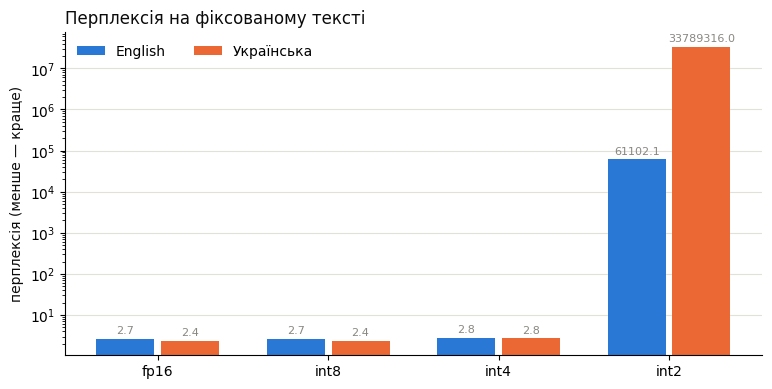

In [22]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

Переклади всіх варіантів поруч з еталоном:

In [23]:
translations = pd.DataFrame({"еталон": [ref for _, ref in TRANSLATION]}, index=[src for src, _ in TRANSLATION])
for name, r in records.items():
    translations[name] = r["переклади"]
translations

,еталон,fp16,int8,int4,int2
The meeting has been moved to Thursday at three o'clock.,Зустріч перенесли на четвер на третю годину.,"Зустріч була перенесена на четвер, о 15 годин.","Зустріч перенесли на четвер, о 15 годин.","Зустріч була перенесена на четвер, о 15 годин.",``thrown\nbetween 'ever'oft' \neverhosterone'...
Please send me the report by the end of the day.,"Будь ласка, надішліть мені звіт до кінця дня.",Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,Надішліть мені звіт до кінця дня.,takenawns between't```````````````````h``` \`e...
The library is closed on Sundays and public holidays.,Бібліотека не працює в неділю та у святкові дні.,Бібліотека закривається у неділі та дні відпоч...,Бібліотека закривається у неділі та дні відпоч...,Бібліотека відкрита тільки з 1 по 7.,`ever �house �take caught}01\xb takent � taken...
"Our team fixed the bug, but the tests are still failing.","Наша команда виправила помилку, але тести все ...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тестування все...","Наша команда виправила баг, але тести все ще н...",fil}'sand ever0}'-'ever'ickets {'ever''}' \\'\...
"It is going to rain tomorrow, so take an umbrella.","Завтра буде дощ, тож візьміть парасольку.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра піде дощ, тому взміть з собою парасольку.","Завтра буде дощ, тому взміть засіб.","}again \ %""樗\ %( firm \"" \ \'' betweenh '\ \..."
"The new model is smaller, but it answers almost as well as the old one.","Нова модель менша, але відповідає майже так са...","Новий модель менший, але відповідає почти так ...","Новий модель менший, але відповідає приблизно ...","Новий модель менший, але відповідає почти так ...","fil��''}\n0. Heaven\n Fil'`0hber°,1 ,1a caught..."
I would like to book a table for two for seven o'clock tonight.,Я хотів би забронювати столик на двох на сьому...,Я бажаю забронювати стіл для двох на сім годин...,Я бажаю забронювати стіл для двох на сім годин...,Я б хотів зареєструвати стіл для двох на 7 год...,``ever``always```comeight`[\n`letic touched`ev...
The price includes breakfast and free Wi-Fi.,У вартість входять сніданок і безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та безкоштовний Wi-Fi.,Ціна включає початок дня та вільний Wi-Fi.,.前所etermineeverh \between betweenever婿 again \...
Students must submit their lab work before the deadline.,Студенти мають здати лабораторну роботу до кін...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати свою лабораторну робот...,Студенти повинні подати лабораторну роботу до ...,"he economistwar"" be1.sever0 } again \ $} \}eve..."
"If the server does not respond, restart it and check the logs.","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...","Якщо сервер не відповідає, перезапустіть його ...",ever. taken againoughtbetweenhtonhhofthhbetwee...


In [24]:
from pprint import pprint
ref = TRANSLATION[3][1]
print("Еталон: ", ref)
for q in ("fp16", "int8", "int4"):
  transl = records[q]["переклади"][3]
  print(q)
  print(f" transl:", transl)
  print(" chrF:", chrf.compute(predictions=[transl], references=[[ref]])["score"])
  print(" BLEU:", bleu.compute(predictions=[transl], references=[[ref]])["score"])

Еталон:  Наша команда виправила помилку, але тести все ще не проходять.
fp16
 transl: Наша команда виправила баг, але тестування все ще не працюють.
 chrF: 60.679148630908585
 BLEU: 24.808415001701817
int8
 transl: Наша команда виправила баг, але тестування все ще не працюють.
 chrF: 60.679148630908585
 BLEU: 24.808415001701817
int4
 transl: Наша команда виправила баг, але тести все ще не працюють.
 chrF: 68.45623306101312
 BLEU: 54.52469119630863


### 2.5. Сліпе порівняння: fp16 проти int4

Автоматичні метрики показали, наскільки int4 відрізняється від fp16 у числах. Тепер перевірмо очима — так, як це роблять оцінювачі-люди: для кожного запиту показуємо дві відповіді, fp16 та int4, **у випадковому порядку й без підписів**. Ваше завдання — обрати кращу.

In [25]:
rng = np.random.default_rng(0)
BLIND_ORDER = [rng.permutation(["fp16", "int4"]) for _ in GEN_PROMPTS]

for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for label, name in zip("AB", BLIND_ORDER[i]):
        display(Markdown(f"**Відповідь {label}:**\n\n{records[name]['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**Відповідь A:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**Відповідь B:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

**Відповідь A:**

Квантизація нейромережі — це процес зменшення точності ваг між нейронами в мережі, щоб зменшити об’єм пам’яті та швидкість обчислень. Вона полягає у заміні дробових чисел (наприклад, з плаваючою комою) на цілі числа (наприклад, з кількома бітами). Це дозволяє запускати мережі на пристроях з обмеженою відповідністю, таких як мобільні телефони або IoT-апарати. Насправді, квантизація не втрачає повно

**Відповідь B:**

Квантизація нейромережі — це процес зменшення точності ваг (зв'язків між нейронами) до тих рівнів, що можна зберігати в комп'ютері з мінімальним використанням пам'яті. Це робиться для швидкого виконання моделей, особливо на пристроях з обмеженою відповідністю. Квантизація зменшує розмір ваг, змінюючи їх з плавних чисел (наприклад, 32-біт) до цілих або змінних (наприклад,

... (5 outputs left out)

**Відповідь B:**

Ось чіткий і практичний план підготовки до іспиту з програмування на 5 днів — по одному ключовому темі на день. Цей план призначений для студентів, які вивчають програмування на початковому або середньому рівні (наприклад, на мові Python, Java або C++), але може бути адаптований під будь-яку мову.

---

**День 1: Основні структури даних та їх використання**

- Повторити: змінні, типи даних, оператори, вирази.
- Вивчити: списки, кортежі, слов

---
#### Запит 5: Write a Python function that checks whether a string is a palindrome.

**Відповідь A:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**Відповідь B:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

Для кожного запиту запишіть **"A"** або **"B"** — яка відповідь краща, або **"="**, якщо однакові за якістю. Потім запустіть наступну клітинку, щоб дізнатися, де була яка модель.

In [26]:
VOTES = {1: "A", 2: "A", 3: "B", 4: "A", 5: "A"}

In [27]:
if all(v in ("A", "B", "=") for v in VOTES.values()):
    rows = []
    for i, vote in VOTES.items():
        order = dict(zip("AB", BLIND_ORDER[i - 1]))
        rows.append({"запит": GEN_PROMPTS[i - 1], "A": order["A"], "B": order["B"],
                     "ваш вибір": "однаково" if vote == "=" else order[vote]})
    display(pd.DataFrame(rows))
    choices = [r["ваш вибір"] for r in rows]
    print(f"fp16 краща: {choices.count('fp16')}, int4 краща: {choices.count('int4')}, однаково: {choices.count('однаково')}")
else:
    print('Заповніть VOTES значеннями "A", "B" або "=" для всіх 5 запитів.')

,запит,A,B,ваш вибір
0,Напиши короткий лист викладачеві з проханням п...,fp16,int4,fp16
1,Поясни студентові першого курсу в 3–4 реченнях...,fp16,int4,fp16
2,Explain in three sentences why the sky is blue.,fp16,int4,int4
3,Склади план підготовки до іспиту з програмуван...,int4,fp16,int4
4,Write a Python function that checks whether a ...,int4,fp16,int4


fp16 краща: 2, int4 краща: 3, однаково: 0


### 2.6. Відповіді всіх варіантів

Тепер, коли сліпе порівняння зроблено, — відповіді всіх варіантів з підписами, включно з int8 та int2. Еталону тут немає, тож читаємо самі.

In [28]:
for i, prompt in enumerate(GEN_PROMPTS):
    display(Markdown(f"---\n#### Запит {i + 1}: {prompt}"))
    for name, r in records.items():
        display(Markdown(f"**{name}:**\n\n{r['генерації'][i]}"))

---
#### Запит 1: Напиши короткий лист викладачеві з проханням перенести здачу лабораторної роботи на тиждень через хворобу.

**fp16:**

Ось приклад короткого і відповідного листа викладачеві:

---

**Лист викладачеві**

Увага, викладаче!

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу. Здача відкладається на [указати дату, наприклад: 10 листопада 2024 року].

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Курс, наприклад: 3 курс, група 12]  

---

Якщо потрібно — можу допомогти адаптувати лист під конкретний предмет або стиль

**int8:**

Ось приклад короткого листа викладачеві:

---

**Дорогий [Ім’я викладача]!**

Прохання перенести здачу лабораторної роботи на наступний тиждень через хворобу.  
Буду дуже вдячний за розуміння та гнучкість.

З повагою,  
[Ваше ім’я]  
[Номер групи]  
[Контактна інформація, якщо потрібно]

---

Цей лист короткий, виразний та відповідає формату прохання. Можна адаптувати під конкретну ситуацію.

**int4:**

Викладачу [Ім’я та прізвище],

Прохання про перенесення здачі лабораторної роботи на наступний тиждень через хворобу.

З повагою,  
[Ваше прізвище, ім’я, номер групи]

**int2:**

°°h\\n again,  ten and whichotten in between win evidence tile between win had between between : : again again again again°\0 again which which had again between again again had again had had had had had had, which which again which9 which which in which   which in which in in in in which } in which Study which in which whichtbhousetbtbtbtbtbtbtbtb,househousehousehousehousehousehouse, in ...house doneettle,sdsdsdsd,uesdsdsd,sduesdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdsdificatesdsd: ...:’:ight ` which which “ which: which which which which which which which which which which which which which which which which which which which which which which which rest which which rest which resthouse :: which which again:sd: which

---
#### Запит 2: Поясни студентові першого курсу в 3–4 реченнях, що таке квантизація нейромережі.

... (15 outputs left out)

**fp16:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int8:**

Sure! Here's a Python function that checks whether a given string is a palindrome:

```python
def is_palindrome(s):
    """
    Check whether a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]

# Example usage:
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
print(is_palindrome("race a car"))                     # False
print(is_palindrome("racecar"))                       # True
```

### Explanation:
- The function removes all non-alphanumeric characters (like spaces, punctuation) and

**int4:**

Sure! Here's a Python function that checks whether a string is a palindrome:

```python
def is_palindrome(s):
    """
    Check if a string is a palindrome (reads the same forwards and backwards).
    
    Args:
        s (str): The string to check.
    
    Returns:
        bool: True if the string is a palindrome, False otherwise.
    
    Note:
        This function is case-insensitive and ignores non-alphanumeric characters.
    """
    # Remove non-alphanumeric characters and convert to lowercase
    cleaned = ''.join(char.lower() for char in s if char.isalnum())
    
    # Check if the cleaned string reads the same forwards and backwards
    return cleaned == cleaned[::-1]
```

### Example usage:

```python
print(is_palindrome("racecar"))        # True
print(is_palindrome("A man a plan a canal Panama"))  # True
print(is_palindrome("hello"))         # False
print(is_palindrome

**int2:**

\' \ \ \' 
 \ 0\' \ \'\'\'\'\'\'\'\'\'\' \ \ \ \ \ \ \ \ navigator \ \ 
 \ - DS  - - - - - - - - - - - - ~ ~ ~ taken  \ \ \ \ between \  hatchirst \ \\'\' \ - - - \INE \ \ -° - IN - between - found -国民  \ own%\ mark mark mark mark  mark mark mark             \ \          mark mark mark``h  \ mark mark mark mark mark  mark mark mark mark Mark Mark Mark Mark Mark attached  \ \  mark mark mark mark mark mark mark mark mark mark mark. mark mark mark, \ \ \ \ \n \   Paper mark, - \ mark\xb\xb \ \ - mark\n \ \ \ mark. \ Paper\n投 - \ \

In [33]:
import re, random

gc.collect(); torch.cuda.empty_cache()
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE)

for lang, text in PPL_TEXT.items():
    words = re.findall(r"\w+", text.lower())
    shuffled = words[:]
    random.Random(0).shuffle(shuffled)
    print("Мова:", lang)
    print(" Перплексія для осмисленого тексту:", round(perplexity(model, text), 2))
    print(" Перплексія для випадкового порядку слів:", round(perplexity(model, " ".join(shuffled)), 2))

del model

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Мова: English
 Перплексія для осмисленого тексту: 2.67
 Перплексія для випадкового порядку слів: 308.79
Мова: Українська
 Перплексія для осмисленого тексту: 2.4
 Перплексія для випадкового порядку слів: 12.84


## 3.0 Квантизація з Qwen/Qwen3-1.7B

In [34]:
MODEL_ID = "Qwen/Qwen3-1.7B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

VARIANTS = {
    "fp16": None,
    "int8": QuantoConfig(weights="int8"),
    "int4": QuantoConfig(weights="int4"),
    "int2": QuantoConfig(weights="int2"),
}

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

In [35]:
records = {}
for name, config in VARIANTS.items():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE, device_map=DEVICE, quantization_config=config)

    r = {"памʼять моделі, GB": torch.cuda.memory_allocated() / 1e9}
    for lang, text in PPL_TEXT.items():
        r[f"перплексія, {lang}"] = perplexity(model, text)
    r["переклади"] = [generate(model, TRANSLATE_PROMPT.format(src), 80)[0] for src, _ in TRANSLATION]
    generations = [generate(model, prompt, 200) for prompt in GEN_PROMPTS]
    r["генерації"] = [text for text, _, _ in generations]
    r["tokens/s"] = sum(n for _, n, _ in generations) / sum(s for _, _, s in generations)
    r["пік VRAM, GB"] = torch.cuda.max_memory_allocated() / 1e9
    records[name] = r
    print(f"{name}: готово")

    del model

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

fp16: готово


... (2 outputs left out)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int4: готово


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

int2: готово


In [36]:
chrf = evaluate.load("chrf")
bleu = evaluate.load("sacrebleu")
references = [[ref] for _, ref in TRANSLATION]

summary_small = pd.DataFrame({
    name: {
        "памʼять моделі, GB": r["памʼять моделі, GB"],
        "пік VRAM, GB": r["пік VRAM, GB"],
        "tokens/s": r["tokens/s"],
        **{f"перплексія, {lang}": r[f"перплексія, {lang}"] for lang in PPL_TEXT},
        "chrF перекладу": chrf.compute(predictions=r["переклади"], references=references)["score"],
        "BLEU перекладу": bleu.compute(predictions=r["переклади"], references=references)["score"],
    }
    for name, r in records.items()
}).T.round(2)
summary_small

,"памʼять моделі, GB","пік VRAM, GB",tokens/s,"перплексія, English","перплексія, Українська",chrF перекладу,BLEU перекладу
fp16,3.45,4.38,20.21,4.35,3.09,8.61,0.25
int8,2.04,2.98,10.51,4.46,3.11,9.13,0.25
int4,1.38,2.31,6.75,7.51,5.61,10.10,0.58
int2,1.03,1.96,7.29,441276.94,5894554.50,0.16,0.13


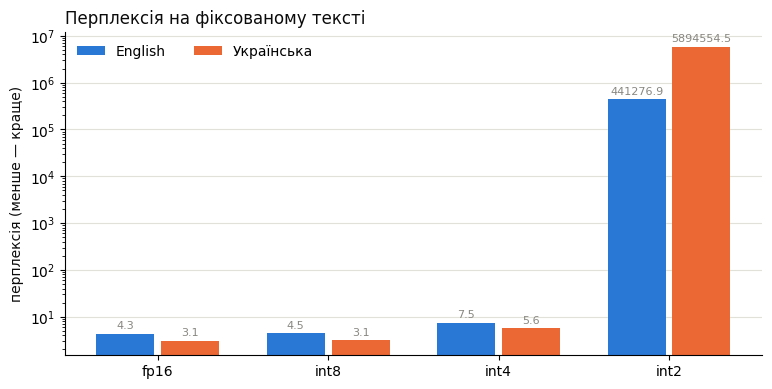

In [37]:
LANG_COLORS = {"English": "#2a78d6", "Українська": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

variants = list(records)
x = np.arange(len(variants))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4.2))
for i, lang in enumerate(PPL_TEXT):
    values = summary_small[f"перплексія, {lang}"].values
    bars = ax.bar(x + (i - 0.5) * width, values, width - 0.04, color=LANG_COLORS[lang], label=lang)
    ax.bar_label(bars, labels=[f"{v:.1f}" for v in values], fontsize=8, color=MUTED, padding=2)
ax.set_yscale("log")
ax.set_xticks(x, variants)
ax.set_ylabel("перплексія (менше — краще)", color=INK)
ax.set_title("Перплексія на фіксованому тексті", loc="left", color=INK)
ax.legend(frameon=False, ncols=2, loc="upper left")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.show()

In [42]:
cols = ["перплексія, English", "перплексія, Українська"]
for name, s in (("4B", summary), ("1.7B", summary_small)):
    print(name)
    print((s.loc[["int8", "int4", "int2"], cols] / s.loc["fp16", cols]).round(2))
    print()

4B
      перплексія, English  перплексія, Українська
int8                 1.00                    1.00
int4                 1.05                    1.15
int2             22884.69             14078881.67

1.7B
      перплексія, English  перплексія, Українська
int8                 1.03                    1.01
int4                 1.73                    1.82
int2            101442.97              1907622.82



# Звіт

## 1. Залізо

| Характеристика | Значення
|---|---
| Процесор (CPU) | AMD Ryzen 5 7535HS
| Оперативна пам’ять (RAM) | 16.0 GB DDR5; доступно Windows — 15.2 GB
| Відеокарта (GPU) | NVIDIA GeForce RTX 4060 Laptop GPU
| Відеопам’ять (VRAM) | 8 GB GDDR6
| Теоретична пропускна здатність VRAM | 256.0 GB/s

## 2. Розрахунок

### Розрахунок потрібної пам'яті при заданій кількості параметрів (Parameters, B) моделі та кількості бітів на параметр (Bit Precision, bit)
Формула: Памʼять (GB) ≈ P × Q/8 × (1 + O)

Припускаємо що Q = 20%

| Розмір моделі | Формат ваг | Пам’ять | Попередній висновок для 8 GB VRAM |
|---|---|---:|---|
| 3B | FP16/BF16 | 7.2 GB | Близько до межі |
| 4B | FP16/BF16 | 9.6 GB | Повністю не вміститься |
| 4B | FP8/INT8 | 4.8 GB | Перспективний варіант |
| 4B | FP4/INT4 | 2.4 GB | Перспективний варіант |
| 8B | FP4/INT4 | 4.8 GB | Перспективний варіант |
| 8B | FP8/INT8 | 9.6 GB | Повністю не вміститься |
| 14B | FP4/INT4 | 8.4 GB | Повністю не вміститься |

### [Local LLM speed calculator](https://martinalderson.com/posts/local-llm-speed-calculator/)

Усі оцінки отримано для 8 GB VRAM, пропускної здатності 200 GB/s і KV-кешу 100 KB на токен.

| № | Параметри моделі | Формат ваг | Контекст, токенів | Ваги, GB | KV-кеш, GB | Загальна пам’ять, GB | Прогноз швидкості, tokens/sec |
|---|---|---|---:|---:|---:|---:|---:|
| 1 | 3B | FP16 | 4096 | 6.00 | 0.41 | 6.41 | 31.2 |
| 2 | 4B | INT8 | 4096 | 4.00 | 0.41 | 4.41 | 45.4 |
| 3 | 4B | INT4 | 4096 | 2.00 | 0.41 | 2.41 | 83.0 |
| 4 | 8B | INT4 | 4096 | 4.00 | 0.41 | 4.41 | 45.4 |
| 5 | 8B | INT4 | 8192 | 4.00 | 0.82 | 4.82 | 41.5 |
| 6 | 8B | INT8 | 4096 | 8.00 | 0.41 | 8.41 | 22.4 |
| 7 | 14B | INT4 | 4096 | 7.00 | 0.41 | 7.41 | 27.0 |

## 3. Обрана модель, квантизація й рантайм і чому

Для запуску обрано Ollama, оскільки цей рантайм дозволяє швидко завантажити й запустити локальну модель без складного налаштування.

Обрана модель: Gemma 3 4B, тег gemma3:4b, https://ollama.com/library/gemma3:4b

Модель має приблизно 4 млрд параметрів, підтримує текстові запити та зображення й доступна в квантизації Q4_K_M. У каталозі зазначено близько 3.88 млрд параметрів мовної частини та додатковий компонент обробки зображень на 420 млн параметрів. Пакет моделі займає приблизно 3.4 GB, що робить її придатним кандидатом для відеокарти з 8 GB VRAM. Додаткова пам’ять потрібна для KV-кешу, обробки зображень і роботи рантайму.

## 4. Вимірювання до оптимізації

In [4]:
import os
from pathlib import Path

ollama_dir = Path(os.environ["LOCALAPPDATA"]) / "Programs" / "Ollama"
ollama_exe = ollama_dir / "ollama.exe"

print("Шлях:", ollama_exe)
print("Файл існує:", ollama_exe.is_file())

Шлях: C:\Users\denli\AppData\Local\Programs\Ollama\ollama.exe
Файл існує: True


In [5]:
!"{ollama_exe}" --version
!"{ollama_exe}" show gemma3:4b

ollama version is 0.40.12
  Model
    architecture        gemma3         
    parameters          3.9B           
    context length      131072         
    embedding length    2560           
    quantization        Q4_K_M         
    requires            0.30.0         
    template source     go_template    

  Capabilities
    completion    
    vision        

  Projector
    architecture        clip       
    parameters          419.82M    
    embedding length    1152       
    dimensions          2560       

  Parameters
    stop           "<end_of_turn>"    
    temperature    1                  
    top_k          64                 
    top_p          0.95               

  License
    Gemma Terms of Use                  
    Last modified: February 21, 2024    
    ...                                 



In [10]:
!python --version

Python 3.14.6


In [11]:
!python bench.py --base-url http://localhost:11434/v1 --model gemma3:4b --label before

Прогрів: gemma3:4b на http://localhost:11434/v1
 клієнтів  помилок  TTFT p50  TTFT p95  tok/s на кор.  throughput
        1        0     2.14с     2.15с           68.3        35.8
        2        0     2.65с     4.02с           76.4        63.2
        4        0     6.00с     8.27с           73.8        69.7
        8        0    15.01с    15.86с           71.8        67.0
Результати дописано в bench_results.csv


В пункті 2 схожа за розмірами на gemmar3:4b модель з параметрами 4B INT4 мала прогнозовану швидкість 83.0 tokens/sec. Фактична заміряна швидкість для gemmar3:4b з одним клієнтом склала  68.3 tok/s на кор, що на приблизно 18% менше. Цю різницю можна пояснити багатьма припущеннями, які робить калькулятор як-от:
- Розмір ваг. Для умовної 4B INT4 калькулятор використав значення 2.4 GB. Реальний пакет gemma3:4b, включно з компонентом для зображень, займає приблизно 3.4 GB.
- KV-кеш. Значення 100 KB/token в калькуляторі було умовним. Його фактичний обсяг і кількість прочитаних даних залежать від архітектури та поточної довжини контексту.
- Витрати обчислень. Калькулятор оцінює переважно обмеження пам’яті, тоді як реальний запуск виконує також обчислення, обробку квантизованих ваг і передавання результатів через API.

In [7]:
tests = {
    "blacksmithing.jpg": (
        "Опиши дію на фотографії у 2–3 реченнях. "
        "Назви видимі інструменти та поясни, як їх використовують. "
        "Не припускай країну чи місце знімання."
    ),
    "blurred_flowers.jpg": (
        "Опиши, що можна розпізнати на фотографії. "
        "Оціни чіткість зображення та зазнач, "
        "які деталі неможливо впевнено визначити."
    ),
    "landscape.jpg": (
        "Напиши короткий опис пейзажу для фотогалереї. "
        "Згадай передній і задній плани та стан неба. "
        "Не визначай географічне місце без достатніх ознак."
    ),
    "objects.jpg": (
        "Перелічи основні геометричні фігури на зображенні "
        "та колір кожної. Потім коротко опиши "
        "розташування двох фігур одна відносно одної."
    ),
    "red_panda.jpg": (
        "Визнач тварину на фотографії, якщо можеш зробити це впевнено. "
        "Опиши її забарвлення, позу та оточення у 2–3 реченнях. "
        "Якщо назва тварини викликає сумнів, зазнач це."
    ),
    "room.jpg": (
        "Опиши кімнату для оголошення про житло у трьох реченнях: "
        "основні меблі, їхнє розташування та кольори інтер’єру. "
        "Використовуй лише видимі характеристики."
    ),
    "street.jpg": (
        "Опиши міську вулицю у 2–3 реченнях. "
        "Згадай забудову, дорожню розмітку та видимий рух. "
        "Не перебільшуй кількість автомобілів і пішоходів."
    ),
    "umbrella.png": (
        "Склади опис предмета для каталогу у двох реченнях. "
        "Назви предмет, його колір, форму та особливості ручки. "
        "Не стверджуй матеріал, якщо його неможливо впевнено визначити."
    ),
    "woman.jpg": (
        "Напиши нейтральний опис портретної фотографії "
        "у двох реченнях: зовнішні ознаки, одяг і фон. "
        "Не припускай професію, характер або особистість людини."
    ),
    "cat.jpg": (
        "Напиши короткий підпис до фотографії для соцмережі: "
        "до 15 слів, без хештегів. "
        "Підпис має відображати видимі особливості тварини, "
        "без вигаданої історії та визначення породи."
    ),
}

In [ ]:
import sys
import subprocess
from pathlib import Path
from datetime import datetime
import csv
import re

model = "gemma3:4b"
label = "before"
temperature = 0.2
seed = 1
max_tokens = 300

image_dir = Path("images").resolve()
script_path = Path("stream_demo.py").resolve()

print("Прогрів моделі:", model)
!python stream_demo.py --base-url http://localhost:11434/v1 --model "{model}" --prompt "Привіт"

if not script_path.is_file():
    raise FileNotFoundError(f"Не знайдено скрипт: {script_path}")

missing = [
    filename
    for filename in tests
    if not (image_dir / filename).is_file()
]

if missing:
    raise FileNotFoundError(
        "Не знайдено зображення: " + ", ".join(missing)
    )

results_dir = Path("test_results/")
results_dir.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
report_path = results_dir / f"quality_{label}_{timestamp}.csv"

columns = [
    "label",
    "model",
    "image",
    "prompt",
    "temperature",
    "seed",
    "max_tokens",
    "response",
    "ttft_s",
    "tokens_per_s",
    "tokens",
    "total_latency_s",
    "return_code",
    "raw_output",
    "quality_notes",
]

errors = 0

with report_path.open("w", encoding="utf-8-sig", newline="") as report:
    writer = csv.DictWriter(report, fieldnames=columns)
    writer.writeheader()

    for index, (filename, task) in enumerate(tests.items(), start=1):
        image_path = image_dir / filename
        prompt = (
            "Відповідай українською. "
            "Спирайся лише на видимі ознаки зображення. "
            + task
        )

        print(f"\n{'=' * 60}")
        print(f"Тест {index}/{len(tests)}: {filename}")
        print("Промпт:", prompt)
        print()

        command = [
            sys.executable,
            "-X", "utf8",
            "-u", str(script_path),
            "--base-url", "http://localhost:11434/v1",
            "--model", model,
            "--prompt", prompt,
            "--image", str(image_path),
            "--temperature", str(temperature),
            "--seed", str(seed),
            "--max-tokens", str(max_tokens),
        ]

        output_lines = []

        with subprocess.Popen(
            command,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            encoding="utf-8",
            errors="replace",
            bufsize=1,
        ) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                output_lines.append(line)

            return_code = process.wait()

        raw_output = "".join(output_lines)

        metrics_start = re.search(
            r"^TTFT:\s+\d", raw_output, flags=re.MULTILINE
        )

        if metrics_start:
            response = raw_output[:metrics_start.start()].strip()
            metrics_text = raw_output[metrics_start.start():]
        else:
            response = raw_output.strip() if return_code == 0 else ""
            metrics_text = ""

        def extract_metric(name):
            match = re.search(
                rf"^{re.escape(name)}:\s*([0-9]+(?:\.[0-9]+)?)",
                metrics_text,
                flags=re.MULTILINE,
            )
            return match.group(1) if match else ""

        if return_code != 0:
            errors += 1
            print(f"Помилка запуску: код {return_code}")

        writer.writerow({
            "label": label,
            "model": model,
            "image": filename,
            "prompt": prompt,
            "temperature": temperature,
            "seed": seed,
            "max_tokens": max_tokens,
            "response": response,
            "ttft_s": extract_metric("TTFT"),
            "tokens_per_s": extract_metric("tokens/s"),
            "tokens": extract_metric("токенів"),
            "total_latency_s": extract_metric("повна затримка"),
            "return_code": return_code,
            "raw_output": raw_output,
            "quality_notes": "",
        })
        report.flush()

print(f"\nЗавершено. Помилок запуску: {errors}")
print("CSV збережено:", report_path.resolve())

Прогрів моделі: gemma3:4b


Привіт! Радий тебе бачити. Чим я можу допомогти сьогодні? 😊


TTFT:             9.33 с
tokens/s:         65.8
токенів:          20
повна затримка:   9.62 с

Тест 1/10: blacksmithing.jpg
Промпт: Відповідай українською. Спирайся лише на видимі ознаки зображення. Опиши дію на фотографії у 2–3 реченнях. Назви видимі інструменти та поясни, як їх використовують. Не припускай країну чи місце знімання.

На фотографії зображено процес кування металу. Рука з допомогою молотка оббиває розпечену сталеву балку, яка лежить на ковадлі.  Ковадель використовується для формування металу шляхом обтікання та переміщення його під час удару молотком.

TTFT:             3.78 с
tokens/s:         68.1
токенів:          70
повна затримка:   4.80 с

Тест 2/10: blurred_flowers.jpg
Промпт: Відповідай українською. Спирайся лише на видимі ознаки зображення. Опиши, що можна розпізнати на фотографії. Оціни чіткість зображення та зазнач, які деталі неможливо впевнено визначити.

На фотографії видно дві квіти, ймовірно,

In [3]:
import pandas as pd

results = pd.read_csv(report_path)

display(results[[
    "image",
    "response",
    "ttft_s",
    "tokens_per_s",
    "total_latency_s",
]])

,image,response,ttft_s,tokens_per_s,total_latency_s
0,blacksmithing.jpg,На фотографії зображено процес кування металу....,3.78,68.1,4.80
1,blurred_flowers.jpg,"На фотографії видно дві квіти, ймовірно, троян...",3.32,68.3,5.32
2,landscape.jpg,"Зелені пагорби з низькими терасами, вкриті тра...",3.38,66.6,4.72
3,objects.jpg,На зображенні присутні такі геометричні фігури...,3.31,69.0,4.89
4,red_panda.jpg,На фотографії зображена червона панда. Вона си...,3.38,69.0,4.52
5,room.jpg,У кімнаті розташована велика червона ліжко з б...,3.27,68.3,4.63
6,street.jpg,"На зображенні – широка міська вулиця, що веде ...",3.39,69.2,4.59
7,umbrella.png,Це червоний парасолька з округлою формою. Ручк...,3.39,69.2,3.98
8,woman.jpg,На фотографії зображена молода жінка з довгим ...,3.28,69.0,4.03
9,cat.jpg,Маленький котик з красивими блакитними очима т...,3.31,67.0,3.73


Модель генерувала описи фотографій з середньою швидкістю близько 68.4 tokens/s. Середній час до першого токена становив 3.38 с, повний час відповіді - 4.52 с. Модель переважно розпізнавала основні об’єкти, але допускала помилки в деталях та українській граматиці. 

## 5. Оптимізація і вимірювання після

### gemma3:4b-it-q8_0

In [8]:
!"{ollama_exe}" --version
!"{ollama_exe}" show gemma3:4b-it-q8_0

ollama version is 0.40.12
  Model
    architecture        gemma3         
    parameters          3.9B           
    context length      131072         
    embedding length    2560           
    quantization        Q8_0           
    requires            0.30.0         
    template source     go_template    

  Capabilities
    completion    
    vision        

  Projector
    architecture        clip       
    parameters          419.82M    
    embedding length    1152       
    dimensions          2560       

  Parameters
    temperature    1                  
    top_k          64                 
    top_p          0.95               
    stop           "<end_of_turn>"    

  License
    Gemma Terms of Use                  
    Last modified: February 21, 2024    
    ...                                 



In [9]:
!python bench.py --base-url http://localhost:11434/v1 --model gemma3:4b-it-q8_0 --label after_q8

Прогрів: gemma3:4b-it-q8_0 на http://localhost:11434/v1
 клієнтів  помилок  TTFT p50  TTFT p95  tok/s на кор.  throughput
        1        0     2.13с     2.17с           48.4        29.1
        2        0     3.78с     4.80с           49.0        44.6
        4        0     9.30с    12.41с           49.0        46.4
        8        0    20.98с    22.29с           48.8        46.3
Результати дописано в bench_results.csv


In [10]:
model = "gemma3:4b-it-q8_0"
label = "after_q8"
temperature = 0.2
seed = 1
max_tokens = 300

image_dir = Path("images").resolve()
script_path = Path("stream_demo.py").resolve()

print("Прогрів моделі:", model)
!python stream_demo.py --base-url http://localhost:11434/v1 --model "{model}" --prompt "Привіт"

if not script_path.is_file():
    raise FileNotFoundError(f"Не знайдено скрипт: {script_path}")

missing = [
    filename
    for filename in tests
    if not (image_dir / filename).is_file()
]

if missing:
    raise FileNotFoundError(
        "Не знайдено зображення: " + ", ".join(missing)
    )

results_dir = Path("test_results/")
results_dir.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
report_path = results_dir / f"quality_{label}_{timestamp}.csv"

columns = [
    "label",
    "model",
    "image",
    "prompt",
    "temperature",
    "seed",
    "max_tokens",
    "response",
    "ttft_s",
    "tokens_per_s",
    "tokens",
    "total_latency_s",
    "return_code",
    "raw_output",
    "quality_notes",
]

errors = 0

with report_path.open("w", encoding="utf-8-sig", newline="") as report:
    writer = csv.DictWriter(report, fieldnames=columns)
    writer.writeheader()

    for index, (filename, task) in enumerate(tests.items(), start=1):
        image_path = image_dir / filename
        prompt = (
            "Відповідай українською. "
            "Спирайся лише на видимі ознаки зображення. "
            + task
        )

        print(f"\n{'=' * 60}")
        print(f"Тест {index}/{len(tests)}: {filename}")
        print("Промпт:", prompt)
        print()

        command = [
            sys.executable,
            "-X", "utf8",
            "-u", str(script_path),
            "--base-url", "http://localhost:11434/v1",
            "--model", model,
            "--prompt", prompt,
            "--image", str(image_path),
            "--temperature", str(temperature),
            "--seed", str(seed),
            "--max-tokens", str(max_tokens),
        ]

        output_lines = []

        with subprocess.Popen(
            command,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            encoding="utf-8",
            errors="replace",
            bufsize=1,
        ) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                output_lines.append(line)

            return_code = process.wait()

        raw_output = "".join(output_lines)

        metrics_start = re.search(
            r"^TTFT:\s+\d", raw_output, flags=re.MULTILINE
        )

        if metrics_start:
            response = raw_output[:metrics_start.start()].strip()
            metrics_text = raw_output[metrics_start.start():]
        else:
            response = raw_output.strip() if return_code == 0 else ""
            metrics_text = ""

        def extract_metric(name):
            match = re.search(
                rf"^{re.escape(name)}:\s*([0-9]+(?:\.[0-9]+)?)",
                metrics_text,
                flags=re.MULTILINE,
            )
            return match.group(1) if match else ""

        if return_code != 0:
            errors += 1
            print(f"Помилка запуску: код {return_code}")

        writer.writerow({
            "label": label,
            "model": model,
            "image": filename,
            "prompt": prompt,
            "temperature": temperature,
            "seed": seed,
            "max_tokens": max_tokens,
            "response": response,
            "ttft_s": extract_metric("TTFT"),
            "tokens_per_s": extract_metric("tokens/s"),
            "tokens": extract_metric("токенів"),
            "total_latency_s": extract_metric("повна затримка"),
            "return_code": return_code,
            "raw_output": raw_output,
            "quality_notes": "",
        })
        report.flush()

print(f"\nЗавершено. Помилок запуску: {errors}")
print("CSV збережено:", report_path.resolve())

Прогрів моделі: gemma3:4b-it-q8_0
Привіт! Чим можу допомогти? 😊


TTFT:             2.56 с
tokens/s:         48.4
токенів:          12
повна затримка:   2.79 с

Тест 1/10: blacksmithing.jpg
Промпт: Відповідай українською. Спирайся лише на видимі ознаки зображення. Опиши дію на фотографії у 2–3 реченнях. Назви видимі інструменти та поясни, як їх використовують. Не припускай країну чи місце знімання.

На фотографії зображено процес кування металу. Рука з допомогою молотка б’є по нагрітому металевому предмету, який лежить на ковадлі.  Вогненне полум’я підкреслює нагрітий метал, а молоток використовується для формування та зміни форми металу.

TTFT:             3.44 с
tokens/s:         48.3
токенів:          74
повна затримка:   4.96 с

Тест 2/10: blurred_flowers.jpg
Промпт: Відповідай українською. Спирайся лише на видимі ознаки зображення. Опиши, що можна розпізнати на фотографії. Оціни чіткість зображення та зазнач, які деталі неможливо впевнено визначити.

На фотографії видно дві квітки

In [11]:
import pandas as pd

results = pd.read_csv(report_path)

display(results[[
    "image",
    "response",
    "ttft_s",
    "tokens_per_s",
    "total_latency_s",
]])

,image,response,ttft_s,tokens_per_s,total_latency_s
0,blacksmithing.jpg,На фотографії зображено процес кування металу....,3.44,48.3,4.96
1,blurred_flowers.jpg,"На фотографії видно дві квітки, які мають роже...",3.36,47.6,6.22
2,landscape.jpg,"На передньому плані – широка, яскраво-зелена г...",3.37,47.1,5.75
3,objects.jpg,На зображенні присутні наступні геометричні фі...,3.43,47.6,6.33
4,red_panda.jpg,На фотографії зображена червона панда. У неї г...,3.24,48.0,4.82
5,room.jpg,У кімнаті є письмовий стіл з кріслом біля вікн...,3.25,48.0,4.92
6,street.jpg,"На зображенні видно широку міську вулицю, яка ...",3.56,46.3,5.07
7,umbrella.png,Це червоний парасолька з округлою формою. Ручк...,3.47,47.4,4.19
8,woman.jpg,На фотографії зображена молода жінка з довгим ...,3.34,47.9,4.42
9,cat.jpg,Маленький котик з красивими блакитними очима т...,3.35,47.8,3.79


Перехід із Q4_K_M на Q8_0 знизив швидкість генерації приблизно на 30%: для одного клієнта — із 68.3 до 48.4 tokens/s, на зображеннях у середньому — із 68.4 до 47.6 tokens/s. Середній TTFT для зображень залишився близько 3.38 с, а повний час відповіді зріс із 4.52 до 5.05 с. Під паралельним навантаженням throughput також зменшився.

Покращення якості були локальними: модель перестала припускати вид розмитих квітів і матеріал ручки парасольки. Водночас залишилися неправильний колір куба, «сережки на шиї» та граматичні помилки «червоний парасолька», «велика червона ліжко». З’явилися й невдалі формулювання: «цілісність (циліндр)», «на стіні висить дерев’яні двері». Отже, на цих 10 прикладах стабільного покращення якості не виявлено, а втрата швидкості суттєва. Q4_K_M наразі має вигідніший баланс продуктивності та якості.

### qwen3-vl:4b-instruct

In [12]:
!"{ollama_exe}" --version
!"{ollama_exe}" show qwen3-vl:4b-instruct

ollama version is 0.40.12
  Model
    architecture        qwen3vl              
    parameters          4.0B                 
    context length      262144               
    embedding length    2560                 
    quantization        Q4_K_M               
    requires            0.30.0               
    renderer            qwen3-vl-instruct    
    parser              qwen3-vl-instruct    
    template source     renderer_parser      

  Capabilities
    completion    
    vision        
    tools         

  Projector
    architecture        clip       
    parameters          415.35M    
    embedding length    1024       
    dimensions          2560       

  Parameters
    temperature    1       
    top_k          20      
    top_p          0.95    

  License
    Apache License               
    Version 2.0, January 2004    
    ...                          



In [13]:
!python bench.py --base-url http://localhost:11434/v1 --model qwen3-vl:4b-instruct --label after_qwen

Прогрів: qwen3-vl:4b-instruct на http://localhost:11434/v1
 клієнтів  помилок  TTFT p50  TTFT p95  tok/s на кор.  throughput
        1        0     2.10с     2.13с           71.6        36.8
        2        0     2.73с     4.73с           74.1        62.0
        4        0     6.33с     8.84с           73.6        68.6
        8        0    14.85с    17.78с           73.2        68.4
Результати дописано в bench_results.csv


In [16]:
model = "qwen3-vl:4b-instruct"
label = "after_qwen"
temperature = 0.2
seed = 1
max_tokens = 300

image_dir = Path("images").resolve()
script_path = Path("stream_demo.py").resolve()

print("Прогрів моделі:", model)
!python stream_demo.py --base-url http://localhost:11434/v1 --model "{model}" --prompt "Привіт"

if not script_path.is_file():
    raise FileNotFoundError(f"Не знайдено скрипт: {script_path}")

missing = [
    filename
    for filename in tests
    if not (image_dir / filename).is_file()
]

if missing:
    raise FileNotFoundError(
        "Не знайдено зображення: " + ", ".join(missing)
    )

results_dir = Path("test_results/")
results_dir.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
report_path = results_dir / f"quality_{label}_{timestamp}.csv"

columns = [
    "label",
    "model",
    "image",
    "prompt",
    "temperature",
    "seed",
    "max_tokens",
    "response",
    "ttft_s",
    "tokens_per_s",
    "tokens",
    "total_latency_s",
    "return_code",
    "raw_output",
    "quality_notes",
]

errors = 0

with report_path.open("w", encoding="utf-8-sig", newline="") as report:
    writer = csv.DictWriter(report, fieldnames=columns)
    writer.writeheader()

    for index, (filename, task) in enumerate(tests.items(), start=1):
        image_path = image_dir / filename
        prompt = (
            "Відповідай українською. "
            "Спирайся лише на видимі ознаки зображення. "
            + task
        )

        print(f"\n{'=' * 60}")
        print(f"Тест {index}/{len(tests)}: {filename}")
        print("Промпт:", prompt)
        print()

        command = [
            sys.executable,
            "-X", "utf8",
            "-u", str(script_path),
            "--base-url", "http://localhost:11434/v1",
            "--model", model,
            "--prompt", prompt,
            "--image", str(image_path),
            "--temperature", str(temperature),
            "--seed", str(seed),
            "--max-tokens", str(max_tokens),
        ]

        output_lines = []

        with subprocess.Popen(
            command,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            encoding="utf-8",
            errors="replace",
            bufsize=1,
        ) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                output_lines.append(line)

            return_code = process.wait()

        raw_output = "".join(output_lines)

        metrics_start = re.search(
            r"^TTFT:\s+\d", raw_output, flags=re.MULTILINE
        )

        if metrics_start:
            response = raw_output[:metrics_start.start()].strip()
            metrics_text = raw_output[metrics_start.start():]
        else:
            response = raw_output.strip() if return_code == 0 else ""
            metrics_text = ""

        def extract_metric(name):
            match = re.search(
                rf"^{re.escape(name)}:\s*([0-9]+(?:\.[0-9]+)?)",
                metrics_text,
                flags=re.MULTILINE,
            )
            return match.group(1) if match else ""

        if return_code != 0:
            errors += 1
            print(f"Помилка запуску: код {return_code}")

        writer.writerow({
            "label": label,
            "model": model,
            "image": filename,
            "prompt": prompt,
            "temperature": temperature,
            "seed": seed,
            "max_tokens": max_tokens,
            "response": response,
            "ttft_s": extract_metric("TTFT"),
            "tokens_per_s": extract_metric("tokens/s"),
            "tokens": extract_metric("токенів"),
            "total_latency_s": extract_metric("повна затримка"),
            "return_code": return_code,
            "raw_output": raw_output,
            "quality_notes": "",
        })
        report.flush()

print(f"\nЗавершено. Помилок запуску: {errors}")
print("CSV збережено:", report_path.resolve())

Прогрів моделі: qwen3-vl:4b-instruct
Привіт! 😊  
Як можу вам допомогти? Чи є у вас якісь питання або задачі?

TTFT:             2.39 с
tokens/s:         72.5
токенів:          36
повна затримка:   2.87 с

Тест 1/10: blacksmithing.jpg
Промпт: Відповідай українською. Спирайся лише на видимі ознаки зображення. Опиши дію на фотографії у 2–3 реченнях. Назви видимі інструменти та поясни, як їх використовують. Не припускай країну чи місце знімання.

Металург збив металевий пруток, що горить, з великим молотом, що викликає випромінювання вогню та відблисків. Використовується великий молот для формування металу, а також відкритий пруток, який використовується для вироблення металевої деталі.

TTFT:             2.47 с
tokens/s:         60.6
токенів:          116
повна затримка:   4.36 с

Тест 2/10: blurred_flowers.jpg
Промпт: Відповідай українською. Спирайся лише на видимі ознаки зображення. Опиши, що можна розпізнати на фотографії. Оціни чіткість зображення та зазнач, які деталі неможливо впевн

In [17]:
import pandas as pd

results = pd.read_csv(report_path)

display(results[[
    "image",
    "response",
    "ttft_s",
    "tokens_per_s",
    "total_latency_s",
]])

,image,response,ttft_s,tokens_per_s,total_latency_s
0,blacksmithing.jpg,"Металург збив металевий пруток, що горить, з в...",2.47,60.6,4.36
1,blurred_flowers.jpg,На фотографії зображено дві розмиті квіти світ...,2.37,65.6,6.93
2,landscape.jpg,"На передньому плані — суха, золотиста трава, щ...",2.46,70.0,6.47
3,objects.jpg,Основні геометричні фігури та їх кольори:\n\n1...,2.42,70.2,6.25
4,red_panda.jpg,На фотографії зображено червоного панда — міцн...,2.30,64.8,4.80
5,room.jpg,"Кімната — це спальні з дерев’яним ліжком, покр...",2.33,69.1,4.73
6,street.jpg,Міська вулиця пролягає між високими багатопове...,2.38,70.5,5.00
7,umbrella.png,Це червоний парасоль з кривою ручкою. Ручка ма...,2.53,57.3,3.53
8,woman.jpg,На фотографії зображена жінка з довгими темним...,2.50,59.7,4.06
9,cat.jpg,Маленьке котенок з синіми очима та смугастою ш...,2.35,48.4,2.93


Qwen3-VL 4B Instruct скоротила середній час до першого токена приблизно на 29% порівняно з Gemma Q4_K_M. У текстовому бенчмарку швидкість для одного клієнта зросла приблизно на 5%, проте throughput під навантаженням залишився близьким. Повний час опису зображень трохи збільшився, зокрема через довші відповіді.
Покращення опису фото виявились неоднозначними неоднозначно: модель краще розпізнала окремі геометричні фігури та прибрала вигадані «сережки на шиї». Водночас залишилися неточності й помітні мовні помилки: «Маленьке котенок», «ліadderкою», «підйомного ковпачка». Опис розмитих квітів містив повторення та обірвався на ліміті 300 токенів. Отже, початок відповіді став швидшим, але стабільного покращення якості українських описів не досягнуто.

### gemma3:4b-it-qat

In [18]:
!"{ollama_exe}" --version
!"{ollama_exe}" show gemma3:4b-it-qat

ollama version is 0.40.12
  Model
    architecture        gemma3         
    parameters          3.9B           
    context length      131072         
    embedding length    2560           
    quantization        Q4_0           
    requires            0.30.0         
    template source     go_template    

  Capabilities
    completion    
    vision        

  Projector
    architecture        clip       
    parameters          419.82M    
    embedding length    1152       
    dimensions          2560       

  Parameters
    stop           "<end_of_turn>"    
    temperature    1                  
    top_k          64                 
    top_p          0.95               



In [19]:
!python bench.py --base-url http://localhost:11434/v1 --model gemma3:4b-it-qat --label after_4b-qat

Прогрів: gemma3:4b-it-qat на http://localhost:11434/v1
 клієнтів  помилок  TTFT p50  TTFT p95  tok/s на кор.  throughput
        1        0     2.14с     2.16с           59.2        32.3
        2        0     3.37с     4.55с           60.6        51.1
        4        0     7.49с    10.04с           60.5        56.8
        8        0    17.11с    17.74с           60.3        56.5
Результати дописано в bench_results.csv


In [20]:
model = "gemma3:4b-it-qat"
label = "after_after_4b-qat"
temperature = 0.2
seed = 1
max_tokens = 300

image_dir = Path("images").resolve()
script_path = Path("stream_demo.py").resolve()

print("Прогрів моделі:", model)
!python stream_demo.py --base-url http://localhost:11434/v1 --model "{model}" --prompt "Привіт"

if not script_path.is_file():
    raise FileNotFoundError(f"Не знайдено скрипт: {script_path}")

missing = [
    filename
    for filename in tests
    if not (image_dir / filename).is_file()
]

if missing:
    raise FileNotFoundError(
        "Не знайдено зображення: " + ", ".join(missing)
    )

results_dir = Path("test_results/")
results_dir.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
report_path = results_dir / f"quality_{label}_{timestamp}.csv"

columns = [
    "label",
    "model",
    "image",
    "prompt",
    "temperature",
    "seed",
    "max_tokens",
    "response",
    "ttft_s",
    "tokens_per_s",
    "tokens",
    "total_latency_s",
    "return_code",
    "raw_output",
    "quality_notes",
]

errors = 0

with report_path.open("w", encoding="utf-8-sig", newline="") as report:
    writer = csv.DictWriter(report, fieldnames=columns)
    writer.writeheader()

    for index, (filename, task) in enumerate(tests.items(), start=1):
        image_path = image_dir / filename
        prompt = (
            "Відповідай українською. "
            "Спирайся лише на видимі ознаки зображення. "
            + task
        )

        print(f"\n{'=' * 60}")
        print(f"Тест {index}/{len(tests)}: {filename}")
        print("Промпт:", prompt)
        print()

        command = [
            sys.executable,
            "-X", "utf8",
            "-u", str(script_path),
            "--base-url", "http://localhost:11434/v1",
            "--model", model,
            "--prompt", prompt,
            "--image", str(image_path),
            "--temperature", str(temperature),
            "--seed", str(seed),
            "--max-tokens", str(max_tokens),
        ]

        output_lines = []

        with subprocess.Popen(
            command,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            encoding="utf-8",
            errors="replace",
            bufsize=1,
        ) as process:
            for line in process.stdout:
                print(line, end="", flush=True)
                output_lines.append(line)

            return_code = process.wait()

        raw_output = "".join(output_lines)

        metrics_start = re.search(
            r"^TTFT:\s+\d", raw_output, flags=re.MULTILINE
        )

        if metrics_start:
            response = raw_output[:metrics_start.start()].strip()
            metrics_text = raw_output[metrics_start.start():]
        else:
            response = raw_output.strip() if return_code == 0 else ""
            metrics_text = ""

        def extract_metric(name):
            match = re.search(
                rf"^{re.escape(name)}:\s*([0-9]+(?:\.[0-9]+)?)",
                metrics_text,
                flags=re.MULTILINE,
            )
            return match.group(1) if match else ""

        if return_code != 0:
            errors += 1
            print(f"Помилка запуску: код {return_code}")

        writer.writerow({
            "label": label,
            "model": model,
            "image": filename,
            "prompt": prompt,
            "temperature": temperature,
            "seed": seed,
            "max_tokens": max_tokens,
            "response": response,
            "ttft_s": extract_metric("TTFT"),
            "tokens_per_s": extract_metric("tokens/s"),
            "tokens": extract_metric("токенів"),
            "total_latency_s": extract_metric("повна затримка"),
            "return_code": return_code,
            "raw_output": raw_output,
            "quality_notes": "",
        })
        report.flush()

print(f"\nЗавершено. Помилок запуску: {errors}")
print("CSV збережено:", report_path.resolve())

Прогрів моделі: gemma3:4b-it-qat
Привіт! Радий тебе бачити. Чим можу допомогти? 😊


TTFT:             2.32 с
tokens/s:         41.7
токенів:          18
повна затримка:   2.72 с

Тест 1/10: blacksmithing.jpg
Промпт: Відповідай українською. Спирайся лише на видимі ознаки зображення. Опиши дію на фотографії у 2–3 реченнях. Назви видимі інструменти та поясни, як їх використовують. Не припускай країну чи місце знімання.

На фотографії зображено процес ковальства. Майстер використовує молот, щоб обшліфувати залізну балку, яка горить від тепла.  Вогненна балка лежить на оправі, а молот обдає її ударами, змінюючи форму металу.

TTFT:             3.63 с
tokens/s:         59.3
токенів:          67
повна затримка:   4.75 с

Тест 2/10: blurred_flowers.jpg
Промпт: Відповідай українською. Спирайся лише на видимі ознаки зображення. Опиши, що можна розпізнати на фотографії. Оціни чіткість зображення та зазнач, які деталі неможливо впевнено визначити.

На фотографії видно дві квітки, ймовірно, тропічн

In [21]:
import pandas as pd

results = pd.read_csv(report_path)

display(results[[
    "image",
    "response",
    "ttft_s",
    "tokens_per_s",
    "total_latency_s",
]])

,image,response,ttft_s,tokens_per_s,total_latency_s
0,blacksmithing.jpg,На фотографії зображено процес ковальства. Май...,3.63,59.3,4.75
1,blurred_flowers.jpg,"На фотографії видно дві квітки, ймовірно, троп...",3.20,59.4,7.04
2,landscape.jpg,"На передньому плані – широка, зелена галявина,...",3.28,58.9,6.04
3,objects.jpg,На зображенні присутні такі основні геометричн...,3.36,59.1,5.68
4,red_panda.jpg,"На фотографії зображено панда, хоча її назва м...",3.25,59.6,5.10
5,room.jpg,"У кімнаті є велике ліжко червоного кольору, ро...",3.29,58.4,4.75
6,street.jpg,На фотографії зображено широку міську вулицю з...,3.20,59.8,4.79
7,umbrella.png,На зображенні представлений червоний парасоль ...,3.32,59.7,3.99
8,woman.jpg,На фото зображена жінка з довгим темним волосс...,3.29,56.1,4.00
9,cat.jpg,"Пухнастий котик з красивими блакитними очима, ...",3.28,59.5,3.77


Gemma 3 4B QAT показала проміжну продуктивність між Q4_K_M та Q8_0. Порівняно з базовою Q4_K_M швидкість генерації описів знизилася приблизно на 14%, а середній повний час відповіді зріс із 4.52 до 4.99 с. Час до першого токена змінився незначно. Якість покращилася локально: в описі жінки зникли вигадані «сережки на шиї», а в описі кімнати виправлено узгодження слова «ліжко». Водночас конус помилково названо трикутником, колір куба залишився неправильним, а назва червоної панди стала менш точною. Збереглися мовні помилки й необґрунтовані припущення. Отже, на цих 10 тестах QAT не продемонструвала стабільного покращення якості, яке виправдовувало б зниження швидкості.

## 6.0 Застосунок — що робить і як працює, параметри генерації.